# AI & GST: Input Tax Credit and Reverse Charge - model notebook
**ICAI Advanced IT project · GSTiQ**

This notebook documents the machine-learning side of the project on the dummy data of five CA-office clients:

1. Dataset overview and the rule engine's ITC classification
2. Expense classifier (TF-IDF + Logistic Regression) - eligible vs blocked u/s 17(5) vs reverse charge
3. Invoice anomaly detection (Isolation Forest + forensic rules)
4. Benford's law test on invoice values
5. Vendor risk scoring
6. ITC forecasting
7. GST Mitra retrieval chatbot

All code lives in `backend/`; the notebook only calls it, so results here are identical to the web app and the API.

In [1]:
import sys, os, json
sys.path.insert(0, os.path.abspath(os.path.join('..', 'backend')))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from common import load_seed, kb, tax_of
import recon_engine, itc_engine, rcm_engine, ai_engine
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
data = load_seed()
P = pd.DataFrame(data['purchases']); B = pd.DataFrame(data['gstr2b']); Cl = pd.DataFrame(data['clients'])
P['gst'] = P[['igst','cgst','sgst','cess']].sum(axis=1)
print(f"{len(Cl)} clients, {len(data['vendors'])} vendors, {len(P)} purchase invoices, {len(B)} GSTR-2B records")

5 clients, 133 vendors, 609 purchase invoices, 474 GSTR-2B records


## 1. Dataset and rule-engine result

In [2]:
summary = P.groupby('client_id').agg(bills=('id','count'), taxable=('taxable_value','sum'), gst=('gst','sum'), rcm_bills=('reverse_charge', lambda s: (s=='Y').sum()))
summary.index = summary.index.map(Cl.set_index('id')['name'])
summary.round(0)

,bills,taxable,gst,rcm_bills
client_id,,,,
Saurashtra Agro Exports Pvt Ltd,137,37426549.0,3587850.0,17
Narmada Infra Projects LLP,136,36371308.0,6954546.0,36
Shree Ganesh Textiles Pvt Ltd,112,29449493.0,3144402.0,17
Konkan Logistics & Warehousing Pvt Ltd,111,14546619.0,2529503.0,24
TechNova Software Solutions Pvt Ltd,113,44412232.0,7916752.0,41


In [3]:
rec = recon_engine.reconcile(data['purchases'], data['gstr2b'], data['vendors'])
ev = pd.DataFrame(itc_engine.evaluate_all(data, recon_results=rec))
status = ev.groupby('status_label').agg(bills=('id','count'), gst=('tax','sum')).sort_values('gst', ascending=False)
status['share_%'] = (status.gst / status.gst.sum() * 100).round(1)
status.round(0)

,bills,gst,share_%
status_label,,,
Eligible,413,13415145.0,56.0
Not in GSTR-2B,53,5183585.0,22.0
Blocked u/s 17(5),63,2994325.0,12.0
Reverse - Rule 37 (180 days),22,1001011.0,4.0
Duplicate entry,4,504783.0,2.0
Deferred,10,388715.0,2.0
Time-barred u/s 16(4),5,181537.0,1.0
Reverse - Rule 37A,3,171672.0,1.0
Ineligible,16,160392.0,1.0


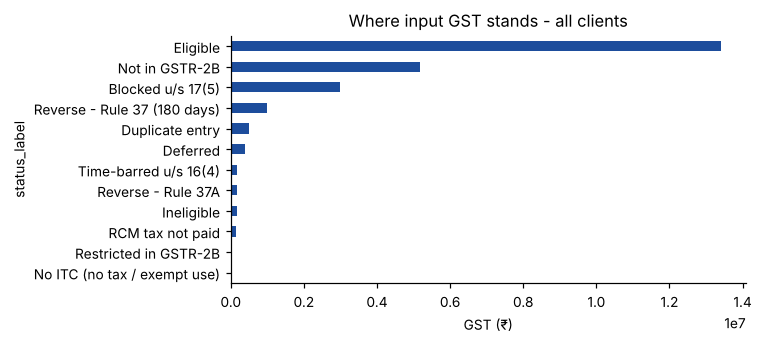

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
status.gst.sort_values().plot.barh(ax=ax, color='#1d4d9c')
ax.set_xlabel('GST (₹)'); ax.set_title('Where input GST stands - all clients')
plt.tight_layout(); plt.show()

## 2. Expense classifier
Ledger narrations are short and inconsistent ("Lorry frt", "freight paid to Sai Roadlines"). A TF-IDF representation of word n-grams and character n-grams feeds a multinomial Logistic Regression. Five-fold stratified cross-validation estimates accuracy on unseen sentences.

In [5]:
clf = ai_engine.ExpenseClassifier()
cv = clf.cross_validate(5); cv

{'folds': 5,
 'mean_accuracy': 0.8504,
 'std': 0.0307,
 'scores': [0.8814, 0.8475, 0.7966, 0.8475, 0.8793],
 'samples': 294,
 'classes': 18}

              precision    recall  f1-score   support

     blocked      0.982     0.865     0.920       126
    eligible      0.675     0.881     0.765        59
         rcm      0.925     0.899     0.912       109

    accuracy                          0.881       294
   macro avg      0.861     0.882     0.865       294
weighted avg      0.899     0.881     0.886       294



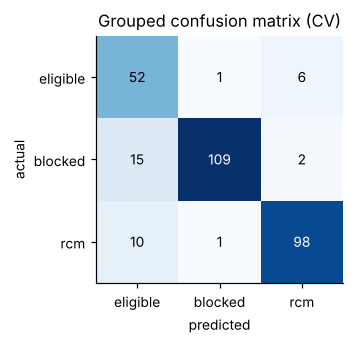

In [6]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report
X = [t for t, _ in kb()['corpus']]; y = [l for _, l in kb()['corpus']]
groups = {l: kb()['labels'][l]['group'] for l in set(y)}
pred = cross_val_predict(clf.model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=7))
yg, pg = [groups[a] for a in y], [groups[b] for b in pred]
print(classification_report(yg, pg, digits=3))
cm = confusion_matrix(yg, pg, labels=['eligible','blocked','rcm'])
fig, ax = plt.subplots(figsize=(3.6, 3.2)); ax.imshow(cm, cmap='Blues')
for i in range(3):
    for j in range(3): ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black')
ax.set_xticks(range(3), ['eligible','blocked','rcm']); ax.set_yticks(range(3), ['eligible','blocked','rcm'])
ax.set_xlabel('predicted'); ax.set_ylabel('actual'); ax.set_title('Grouped confusion matrix (CV)'); plt.tight_layout(); plt.show()

In [7]:
tests = ['Lorry freight paid for inward cotton bales', 'Diwali sweet boxes for dealers', 'AWS invoice for September',
         'Cement for new factory shed', 'Sitting fees to independent director', 'Printer cartridges for accounts']
pd.DataFrame([{'text': r['text'], 'prediction': r['name'], 'confidence': r['confidence'], 'because': ', '.join(r['because'])} for r in clf.predict(tests)])

,text,prediction,confidence,because
0,Lorry freight paid for inward cotton bales,RCM - Goods Transport Agency,0.6364,"freight, inward, freight paid, lorry"
1,Diwali sweet boxes for dealers,Blocked - Gifts / samples / loss,0.5548,"dealers, boxes, for dealers, diwali"
2,AWS invoice for September,RCM - Import of services,0.6475,"invoice, aws, aws invoice"
3,Cement for new factory shed,Blocked - Construction of immovable property,0.5061,"shed, new, cement, cement for"
4,Sitting fees to independent director,RCM - Director services,0.9283,"director, sitting, independent, sitting fees"
5,Printer cartridges for accounts,Eligible ITC,0.8499,"accounts, for accounts, cartridges, printer"


In [8]:
preds = clf.predict(list(P.description))
P['ai_group'] = [p['group'] for p in preds]
P['rule_blocked'] = ev.set_index('id').loc[P.id, 'rule_category'].str.startswith('BLK').values
agree = ((P.ai_group == 'blocked') == P.rule_blocked).mean()
print(f'AI vs rule engine agreement on blocked/not-blocked: {agree:.1%} of {len(P)} real register lines')

AI vs rule engine agreement on blocked/not-blocked: 97.4% of 609 real register lines


## 3. Anomaly detection
Isolation Forest isolates observations with random splits; unusual bills are isolated in fewer splits. Features: log value, deviation from the vendor's mean, round-sum flag, Sunday date, days to payment, proximity to the ₹50,000 e-way bill threshold, rate and month-end. Forensic rules add near-duplicates (same vendor and amount within 10 days).

In [9]:
an = pd.DataFrame(ai_engine.detect_anomalies(data['purchases']))
print(len(an), 'bills flagged')
an[['client_id','supplier_name','invoice_no','taxable_value','score','reasons']].head(12)

30 bills flagged


,client_id,supplier_name,invoice_no,taxable_value,score,reasons
0,C5,Mahalaxmi Computers,DC/2627/0091,16500000.00,1.000,[Value is +3.1σ from this vendor's usual bills...
1,C1,Vardhman Steel Traders,VST/0141/26-27,260230.00,0.919,[Invoice dated on a Sunday]
2,C3,Prime Caterers,PC00270,28844.70,0.901,[Invoice dated on a Sunday]
3,C1,Jalaram Consultants,JC00103,20494.46,0.900,[Same vendor and amount as JC00103 within 10 d...
4,C2,Umiya Builders & Contractors,INV-2627-00383,1242000.00,0.900,[Same vendor and amount as INV-2627-00383 with...
5,C3,Metro Automation,GST/2026-27/398,1475300.56,0.900,[Same vendor and amount as GST/2026-27/398 wit...
6,C4,Kesar Freight Carriers Ltd,GST/2026-27/107,66556.51,0.900,[Same vendor and amount as GST/2026-27/107 wit...
7,C3,Siddhi Yarn Traders,SYT00223,1266698.69,0.885,[Invoice dated on a Sunday]
8,C5,Brightpath Consulting LLC,BCL-202601-0182,150000.00,0.865,[Round-sum invoice value]
9,C5,Meta Platforms Ireland Ltd,MPI-202601-0210,280000.00,0.860,"[Round-sum invoice value, Invoice dated on a S..."


## 4. Benford's law

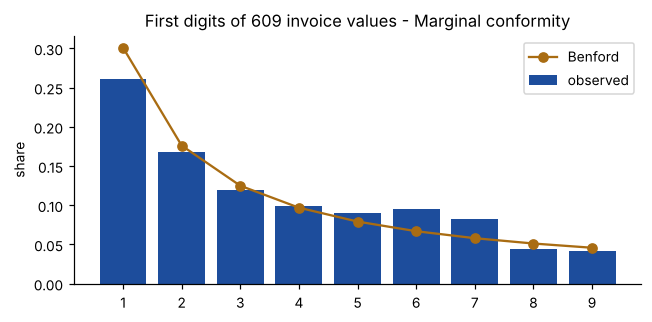

{'chi_square': 18.812,
 'chi_critical_5pct': 15.507,
 'mad': 0.0145,
 'verdict': 'Marginal conformity'}

In [10]:
bf = ai_engine.benford(P.taxable_value.tolist())
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(range(1, 10), bf['observed'], color='#1d4d9c', label='observed')
ax.plot(range(1, 10), bf['expected'], 'o-', color='#a96c12', label="Benford")
ax.set_xticks(range(1, 10)); ax.set_ylabel('share'); ax.legend(); ax.set_title(f"First digits of {bf['n']} invoice values - {bf['verdict']}")
plt.tight_layout(); plt.show()
{k: bf[k] for k in ('chi_square', 'chi_critical_5pct', 'mad', 'verdict')}

## 5. Vendor risk scoring

In [11]:
vr = pd.DataFrame(ai_engine.vendor_risk(data['vendors'], data['purchases'], rec))
print(vr.grade.value_counts().sort_index().to_dict())
vr[['client_id','name','status','score','grade','missing_in_2b','itc_exposure','action']].head(10)

{'A': 97, 'B': 5, 'C': 5, 'D': 5}


,client_id,name,status,score,grade,missing_in_2b,itc_exposure,action
0,C3,Sai Chemicals,Cancelled,89.3,D,4,68531.13,Hold payment / insist on compliance
1,C2,Vishwa Builders & Contractors,Cancelled,86.8,D,5,543142.01,Hold payment / insist on compliance
2,C4,Sahyadri Computers,Cancelled,86.3,D,4,61979.17,Hold payment / insist on compliance
3,C5,Bharat Office Mart,Cancelled,84.8,D,7,15023.12,Hold payment / insist on compliance
4,C1,Deccan Dye Chem,Cancelled,83.3,D,3,96850.18,Hold payment / insist on compliance
5,C1,Vishwa Dye Chem,Active,44.1,C,2,54773.99,Follow up before claiming ITC
6,C4,Kesar Computers,Active,44.1,C,2,50271.83,Follow up before claiming ITC
7,C3,Sunrise Chemicals,Active,41.6,C,3,157184.90,Follow up before claiming ITC
8,C5,Om Computers,Active,40.4,C,3,723094.83,Follow up before claiming ITC
9,C2,Umiya Builders & Contractors,Active,36.2,C,1,1122903.89,Follow up before claiming ITC


## 6. ITC forecast (TechNova Software Solutions)

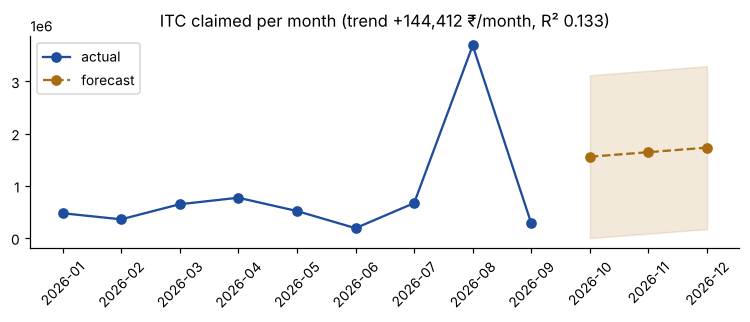

,period,forecast,low,high
0,2026-10,1557100.28,0.00,3116525.17
1,2026-11,1643747.77,84322.88,3203172.65
2,2026-12,1730395.25,170970.37,3289820.13


In [12]:
c5 = P[(P.client_id=='C5') & (P.itc_claimed=='Y') & (P.claim_period>='2026-01')].groupby('claim_period').gst.sum()
fc = ai_engine.forecast_itc(list(c5.items()))
h = pd.DataFrame(fc['history']); f = pd.DataFrame(fc['forecast'])
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(h.period, h.value, 'o-', color='#1d4d9c', label='actual')
ax.plot(f.period, f.forecast, 'o--', color='#a96c12', label='forecast')
ax.fill_between(f.period, f.low, f.high, color='#a96c12', alpha=.15)
ax.set_title(f"ITC claimed per month (trend {fc['slope_per_month']:+,.0f} ₹/month, R² {fc['r2']})"); ax.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()
f

## 7. GST Mitra chatbot

In [13]:
bot = ai_engine.GSTMitra()
for q in ['Can I pay reverse charge from the credit ledger?', 'Is ITC available on a car?', 'What is the time limit to claim ITC?']:
    r = bot.ask(q); print(f"Q: {q}\nA: {r['answer']}\n   (matched '{r.get('matched_question')}', score {r['confidence']})\n")

Q: Can I pay reverse charge from the credit ledger?
A: No. Sec 49(4) allows the electronic credit ledger only for output tax. RCM liability must be paid from the electronic cash ledger. After payment, ITC of the RCM paid is available (subject to Sec 17(5)).
   (matched 'Can RCM be paid through ITC / electronic credit ledger?', score 0.294)

Q: Is ITC available on a car?
A: No, ITC on motor vehicles with seating up to 13 persons is blocked under Sec 17(5)(a) unless used for further supply of vehicles, passenger transport or driving training. Goods vehicles are eligible.
   (matched 'Is ITC available on car purchase?', score 0.411)

Q: What is the time limit to claim ITC?
A: ITC for an invoice must be taken by 30 November following the end of the financial year of the invoice, or the date of filing the annual return (GSTR-9), whichever is earlier. For FY 2025-26 invoices the last date is 30-11-2026.
   (matched 'What is the time limit to claim ITC under section 16(4)?', score 0.467)



## Conclusion
* The deterministic rule engine remains the authority for statutory decisions (Sections 16-17, Rules 36(4), 37, 37A, 42, 43).
* The AI layer adds value where data is unstructured or patterns matter: reading narrations, flagging unusual bills, ranking suppliers and forecasting cash.
* Classifier disagreements with the rule engine are surfaced for human review rather than auto-applied - the same "human in the loop" stance the GST department takes with BIFA/ADVAIT leads.